# 06 · The benchmark: does the graph help?

> Part of the DeepGraph-GBM walk-through. The project is a **benchmark**: it tests whether spatial graph neural networks improve supervised niche prediction in glioblastoma Visium data over matched graph-free models (they do not). See `docs/00_overview_and_roadmap.md`. Notebooks read `data/` (see `docs/WORKFLOW.md`, step A) and the tracked `results/`; none of them trains a model.

This notebook walks through the evidence in the order the paper builds it:

1. a single matched split;
2. six repeated splits (variance only);
3. the leave-one-patient-out benchmark with an equal tuning budget, **the primary analysis**;
4. robustness checks;
5. neuropathologist labels.

Everything is read from tracked run records; nothing is retrained.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path("..").resolve()          # run from notebooks/
PRE = REPO / "data" / "preprocessed"
RES = REPO / "results"
NICHES = ["immune_cold", "immune_hot", "normal", "necrotic"]
COLORS = {"immune_cold": "#D55E00", "immune_hot": "#0072B2", "normal": "#009E73",
          "necrotic": "#CC79A7", "exclude": "#DDDDDD"}
pd.set_option("display.precision", 3)
NAMES = {"logistic": "Logistic", "mlp": "MLP", "mlpnbr": "MLP + neighbours", "sage": "GraphSAGE", "gat": "GAT"}
MCOL = {"Logistic": "#009E73", "MLP": "#0072B2", "MLP + neighbours": "#56B4E9", "GraphSAGE": "#000000", "GAT": "#E69F00"}

## 1. Fixed primary split (Table 1)

In [2]:
t1 = json.load(open(RES / "tables" / "main" / "Table1_model_comparison.json"))
rows = {"GraphSAGE": t1["gnn_multiseed"]["macro_f1"], "MLP": t1["mlp_multiseed"]["macro_f1"],
        "Logistic": t1["logistic_multiseed"]["macro_f1"], "GAT": t1["gat_split0_macro_f1"]}
display(pd.DataFrame(rows).T[["mean", "std"]].rename(columns=lambda c: f"macro-F1 {c}").round(3))
pd.DataFrame(t1["tests_macro_f1"]).T[["test", "mean_diff", "ci95", "t", "df", "p"]]

,macro-F1 mean,macro-F1 std
GraphSAGE,0.489,0.027
MLP,0.578,0.021
Logistic,0.554,0.0
GAT,0.539,0.063


,test,mean_diff,ci95,t,df,p
mlp_vs_gnn,welch_t,0.089,"[0.03305709800645534, 0.1454637614098952]",4.501,3.803,0.012
logistic_vs_gnn,one_sample_t,0.065,"[-0.002113696109557958, 0.1315774984343489]",4.167,2.0,0.053
gat_vs_gnn,welch_t,0.05,"[-0.08481400520477728, 0.185357235793217]",1.263,2.697,0.305


On this split the MLP leads GraphSAGE by 0.089 (Welch p = 0.012). Seeds are not shared units across
models, so a Welch test is used rather than a paired one; the seed-paired p = 0.0017 of earlier versions
was withdrawn. Three seeds on **one** split measure training-seed noise, not patient sampling. The next
section shows why that matters.

## 2. Six patient splits: who is held out matters more than the model

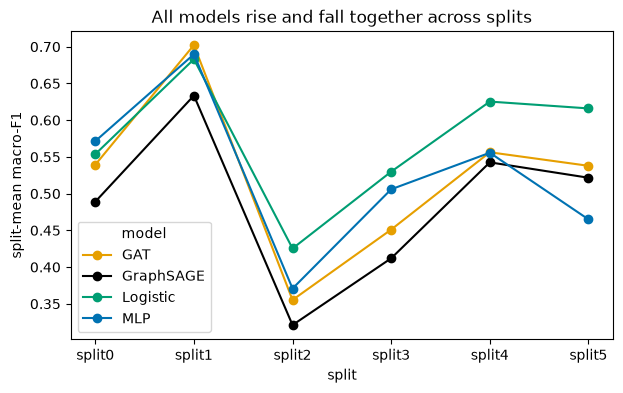

variance of split means / mean within-split seed variance: {'gnn': np.float64(3.6), 'gat': np.float64(3.5), 'mlp': np.float64(8.1)}


In [3]:
s6 = pd.read_csv(RES / "tables" / "supplement" / "TableS6_per_split_metrics.csv")
split_means = s6.groupby(["model", "split"]).macro_f1.mean().unstack(0).rename(columns={"gnn": "GraphSAGE", "gat": "GAT", "mlp": "MLP", "logistic": "Logistic"})
ax = split_means.plot(marker="o", figsize=(7, 4), color=[MCOL[c] for c in split_means.columns])
ax.set_ylabel("split-mean macro-F1"); ax.set_title("All models rise and fall together across splits"); plt.show()
ratio = {m: s6[s6.model == m].groupby("split").macro_f1.mean().var(ddof=1) /
            s6[s6.model == m].groupby("split").macro_f1.var(ddof=1).mean() for m in ("gnn", "gat", "mlp")}
print("variance of split means / mean within-split seed variance:", {k: round(v, 1) for k, v in ratio.items()})

Split-mean macro-F1 spans about 0.3. That is roughly three times the largest gap between models, and
across-split variance is 3.5–8.1× the seed variance. This benchmark is **not** used to rank models: four
of its six threshold-tuning blocks hold fewer than 20 immune-hot spots (notebook 02).

## 3. Leave-one-patient-out with an equal tuning budget (primary analysis)

In [4]:
rev = json.load(open(RES / "revision" / "revision_summary.json"))
L, T = rev["lopo"], rev["lopo_tests"]
tab = pd.DataFrame({NAMES[m]: {"pooled macro-F1": L[m]["pooled_macro_f1_mean"], "SD over seeds": L[m]["pooled_macro_f1_sd"],
                               **{f"AUROC {c}": L[m]["per_class_auroc"][c] for c in NICHES}} for m in NAMES}).T
for m in ("logistic", "mlp", "mlpnbr", "gat"):
    t = T[f"{m}_vs_sage"]
    tab.loc[NAMES[m], "Δ vs GraphSAGE"] = t["pooled_diff"]
    tab.loc[NAMES[m], "95% CI (patient bootstrap)"] = f"{t['pooled_diff_boot95'][0]:+.3f} to {t['pooled_diff_boot95'][1]:+.3f}"
    tab.loc[NAMES[m], "patients ahead"] = f"{t['a_better_patients']}/13"
    tab.loc[NAMES[m], "Wilcoxon p"] = t["wilcoxon_p"]
tab.round(3)

,pooled macro-F1,SD over seeds,AUROC immune_cold,AUROC immune_hot,AUROC normal,AUROC necrotic,Δ vs GraphSAGE,95% CI (patient bootstrap),patients ahead,Wilcoxon p
Logistic,0.691,0.000,0.821,0.968,0.896,0.957,0.039,+0.009 to +0.076,12/13,0.001
MLP,0.655,0.020,0.803,0.892,0.861,0.912,0.003,-0.045 to +0.052,9/13,0.048
MLP + neighbours,0.637,0.047,0.741,0.930,0.786,0.915,-0.015,-0.065 to +0.040,8/13,0.273
GraphSAGE,0.652,0.018,0.769,0.916,0.828,0.923,NaN,NaN,NaN,NaN
GAT,0.649,0.018,0.746,0.897,0.803,0.918,-0.004,-0.032 to +0.018,5/13,0.340


**Logistic regression ranks first** (0.691). It is the only model whose pooled advantage over
GraphSAGE has a bootstrap interval excluding zero (+0.039, 0.009 to 0.076), and it is ahead for 12 of 13
patients. The MLP, GAT and MLP + neighbours are all level with GraphSAGE. Giving the MLP explicit
neighbour-averaged expression does not help it either.

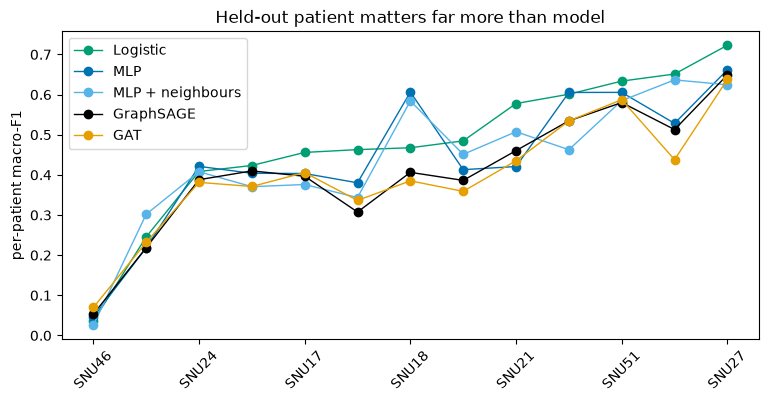

{'Logistic': None, 'MLP': 21.0, 'MLP + neighbours': 4.8, 'GraphSAGE': 16.0, 'GAT': 7.2} (between-patient / seed variance)


In [5]:
pp = pd.DataFrame({NAMES[m]: L[m]["per_patient_macro_f1"] for m in NAMES})
pp = pp.loc[pp.Logistic.sort_values().index]
ax = pp.plot(marker="o", lw=1, figsize=(9, 4), color=[MCOL[c] for c in pp.columns])
ax.set_ylabel("per-patient macro-F1"); ax.set_title("Held-out patient matters far more than model"); plt.xticks(rotation=45); plt.show()
print({NAMES[m]: round(v["ratio"], 1) if v["ratio"] else None for m, v in rev["variance"].items()}, "(between-patient / seed variance)")

Per-patient macro-F1 runs from near zero (SNU46, almost one class) to about 0.7 (SNU27) for **every**
model. The lines move together, so patient identity contributes 5–21× more variance than the seed.

### Two scoring choices that could have flipped the story

In [6]:
s13 = pd.read_csv(RES / "tables" / "supplement" / "TableS13_decision_rule.csv")
s12 = pd.read_csv(RES / "tables" / "supplement" / "TableS12_lopo_support_floor.csv")
display(s13)
s12[["floor", "contrast", "wins", "wilcoxon_p", "wilcoxon_p_holm"]]

,model,pooled_macro_f1_tuned,pooled_macro_f1_argmax,tuned_minus_argmax
0,Logistic,0.691,0.704,-0.013
1,MLP,0.655,0.661,-0.006
2,MLP + neighbors,0.637,0.615,0.022
3,GraphSAGE,0.652,0.633,0.019
4,GAT,0.649,0.614,0.034
5,Logistic - GraphSAGE,0.039,0.071,-0.032
6,MLP - GraphSAGE,0.003,0.028,-0.026


,floor,contrast,wins,wilcoxon_p,wilcoxon_p_holm
0,none (published),Logistic - GraphSAGE,12/13,7.320e-04,0.003
1,none (published),MLP - GraphSAGE,9/13,4.790e-02,0.144
2,none (published),MLP + neighbors - GraphSAGE,8/13,2.730e-01,0.547
3,none (published),GAT - GraphSAGE,5/13,3.400e-01,0.547
4,>= 50 spots,Logistic - GraphSAGE,11/13,1.710e-02,0.068
5,>= 50 spots,MLP - GraphSAGE,8/13,4.140e-01,1.000
6,>= 50 spots,MLP + neighbors - GraphSAGE,7/13,4.700e-01,1.000
7,>= 50 spots,GAT - GraphSAGE,5/13,1.000e+00,1.000
8,>= 200 spots,Logistic - GraphSAGE,10/13,6.810e-02,0.272
9,>= 200 spots,MLP - GraphSAGE,7/13,8.930e-01,1.000


* **Decision rule.** Tuned thresholds *help the graph models* and slightly hurt the graph-free ones.
  Under plain argmax, the logistic lead would be 0.071 instead of 0.039. The protocol the paper uses is
  therefore the conservative one for its conclusion.
* **Per-patient scoring.** Per-patient macro-F1 weights a class with 6 spots like one with 6,000. When a
  minimum class support is required, the MLP's per-patient p = 0.048 disappears, so the paper does not
  claim it. The logistic contrast stays in the same direction at every floor.

## 4. Robustness: nothing rescues the graph

In [7]:
ab = pd.Series({k: v["mean"] for k, v in rev["ablation"].items()})
sage_grid = ab[ab.index.str.startswith("abl_sage")]
sage_grid.index = sage_grid.index.str.replace("abl_sage_", "")
print("GraphSAGE depth x k (mean per-patient macro-F1):"); print(sage_grid.round(3).to_string())
print(f"\none-layer MLP, no graph: {ab['abl_mlp_L1']:.3f}")
mr = pd.DataFrame(rev["marker_removal"]["per_patient_mean_macro_f1"]).rename(columns=NAMES)
mr.index = [f"remove top {i} genes" for i in mr.index]
mr.round(3)

GraphSAGE depth x k (mean per-patient macro-F1):
L1_k12    0.408
L1_k18    0.424
L1_k6     0.425
L2_k12    0.421
L2_k18    0.400
L2_k6     0.382
L3_k12    0.395
L3_k18    0.412
L3_k6     0.404

one-layer MLP, no graph: 0.460


,Logistic,MLP,MLP + neighbours,GraphSAGE
remove top 0 genes,0.448,0.419,0.424,0.404
remove top 100 genes,0.411,0.411,0.409,0.340
remove top 500 genes,0.293,0.253,0.271,0.258


In [8]:
hx = json.load(open(RES / "revision_hex" / "hex_sensitivity.json"))
pd.DataFrame({NAMES[m]: {"published graphs": hx[m]["pooled_orig"][0], "exact hex graphs": hx[m]["pooled_hex"][0],
                         "logistic ahead (patients)": hx[m]["logistic_wins_vs_hex"], "Wilcoxon p": hx[m]["wilcoxon_p_logistic_vs_hex"]}
              for m in ("sage", "gat")}).T.round(4)

,published graphs,exact hex graphs,logistic ahead (patients),Wilcoxon p
GraphSAGE,0.652,0.651,11.0,2.400e-03
GAT,0.648,0.612,12.0,7.000e-04


* **Depth and neighbourhood size.** No GraphSAGE depth or k beats a one-layer MLP without a graph.
* **Marker-gene removal.** If neighbours supplied information a spot lacks, removing the most
  label-associated genes should hurt the graph-free models more. Instead GraphSAGE loses the most, and
  the logistic lead widens.
* **Exact hexagonal geometry.** It helps neither graph model.
* **Homophily.** It is high (0.80; notebook 02), so the graph is informative in principle.

The paper's interpretation: at Visium resolution a spot already pools several cells, and neighbouring
spots have strongly correlated expression, so the neighbourhood largely repeats what the spot already
carries. Aggregation then smooths away small or scattered niches.

## 5. Neuropathologist labels (UKF cohort)

The SNUH labels are derived from expression. This section checks the conclusion against labels drawn
by a neuropathologist on H&E, in 18 patients with five histology classes.

In [9]:
hs = json.load(open(RES / "revision_ukf" / "histology_summary.json"))
NAMES2 = {**NAMES, "mlpnbr": "MLP + neighbours (1 hop)", "mlpnbr2": "MLP + neighbours (2 hops)"}
e1 = hs["E1_ukf_lopo"]
within = pd.DataFrame({NAMES2[m]: {"within-UKF LOPO macro-F1": v["pooled_macro_f1"], "SD": v["pooled_sd"]} for m, v in e1["models"].items()}).T
transfer = pd.DataFrame({NAMES2[m]: {"SNUH→UKF transfer macro-F1": v["macro_f1_tuned"], "SD ": v["macro_f1_tuned_sd"], "mean AUROC": v["mean_auroc"]}
                         for m, v in hs["E2_transfer"].items()}).T
within.join(transfer).round(3)

,within-UKF LOPO macro-F1,SD,SNUH→UKF transfer macro-F1,SD,mean AUROC
Logistic,0.419,0.000,0.352,0.000,0.704
MLP,0.336,0.025,0.380,0.037,0.730
MLP + neighbours (1 hop),0.311,0.030,0.377,0.010,0.740
MLP + neighbours (2 hops),0.346,0.012,0.315,0.073,0.728
GraphSAGE,0.346,0.047,0.395,0.030,0.770
GAT,0.291,0.023,0.315,0.040,0.722


In [10]:
pd.DataFrame({NAMES2[k.replace("_vs_sage", "")]: {"pooled Δ vs GraphSAGE": v["pooled_diff"],
              "95% CI": f"{v['boot95'][0]:+.3f} to {v['boot95'][1]:+.3f}"} for k, v in e1["tests_vs_sage"].items()}).T

,pooled Δ vs GraphSAGE,95% CI
Logistic,0.073,-0.032 to +0.155
MLP,-0.01,-0.061 to +0.033
MLP + neighbours (1 hop),-0.035,-0.077 to +0.008
MLP + neighbours (2 hops),-0.001,-0.062 to +0.067
GAT,-0.056,-0.125 to +0.026


* **Within the cohort**, logistic regression is again first (0.419 vs 0.346 for GraphSAGE), and no
  model differs significantly from GraphSAGE.
* **After transfer** from SNUH's expression-derived labels, GraphSAGE leads (0.395 vs 0.380 for the
  MLP). This is the only setting in the paper where a graph model is ahead. The lead is not significant
  (p = 0.25 vs the MLP), is matched by an MLP given neighbour-averaged features, and depends on input
  scaling.

## Bottom line

Across a matched split, six splits, an equally tuned leave-one-patient-out benchmark, four robustness
checks and independent pathologist labels, **spatial message passing did not improve supervised niche
prediction over per-spot expression**. The paper therefore recommends:

1. tuned graph-free baselines, including a regularised linear model;
2. identical decision rules for every model;
3. patient-level cross-validation;
4. where possible, labels independent of the input expression.

*The retracted "protocol reversal" claim of earlier versions is not part of this analysis; see
`preprint/ANALYSIS_AUDIT.md`.*